# 03 - Modelling

Baselines first: Logistic Regression and Decision Tree. 80/20 split grouped by customer,
tuned with 5-fold CV on the train set. Test set is left alone until the final model.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

from train import models, X_train, y_train, groups, cv
print(X_train.shape, y_train.mean().round(3))

(2721, 33) 0.234


In [2]:
probs = {}
for name, (pipe, params) in models.items():
    grid = GridSearchCV(pipe, params, scoring="roc_auc", cv=cv)
    grid.fit(X_train, y_train, groups=groups)
    probs[name] = cross_val_predict(grid.best_estimator_, X_train, y_train, groups=groups,
                                    cv=cv, method="predict_proba")[:, 1]
    models[name] = grid.best_estimator_
    print(name, grid.best_params_, "AUC:", round(roc_auc_score(y_train, probs[name]), 3))

logistic_regression {'model__C': 0.01} AUC: 0.74


decision_tree {'model__max_depth': 5, 'model__min_samples_leaf': 60} AUC: 0.7


In [3]:
for name, prob in probs.items():
    print(name)
    print(classification_report(y_train, prob >= 0.5, digits=3))

logistic_regression
              precision    recall  f1-score   support

           0      0.870     0.704     0.778      2084
           1      0.404     0.655     0.499       637

    accuracy                          0.693      2721
   macro avg      0.637     0.680     0.639      2721
weighted avg      0.761     0.693     0.713      2721

decision_tree
              precision    recall  f1-score   support

           0      0.863     0.679     0.760      2084
           1      0.381     0.647     0.479       637

    accuracy                          0.671      2721
   macro avg      0.622     0.663     0.619      2721
weighted avg      0.750     0.671     0.694      2721



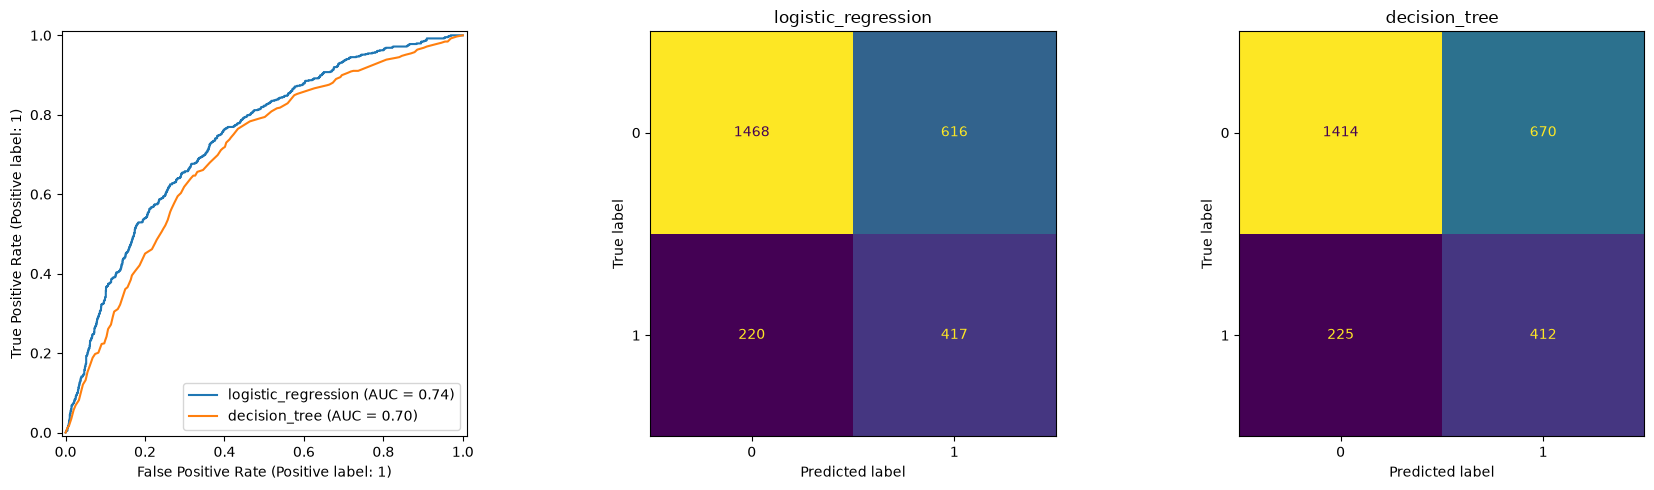

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, prob in probs.items():
    RocCurveDisplay.from_predictions(y_train, prob, name=name, ax=axes[0])
for ax, (name, prob) in zip(axes[1:], probs.items()):
    ConfusionMatrixDisplay.from_predictions(y_train, prob >= 0.5, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()

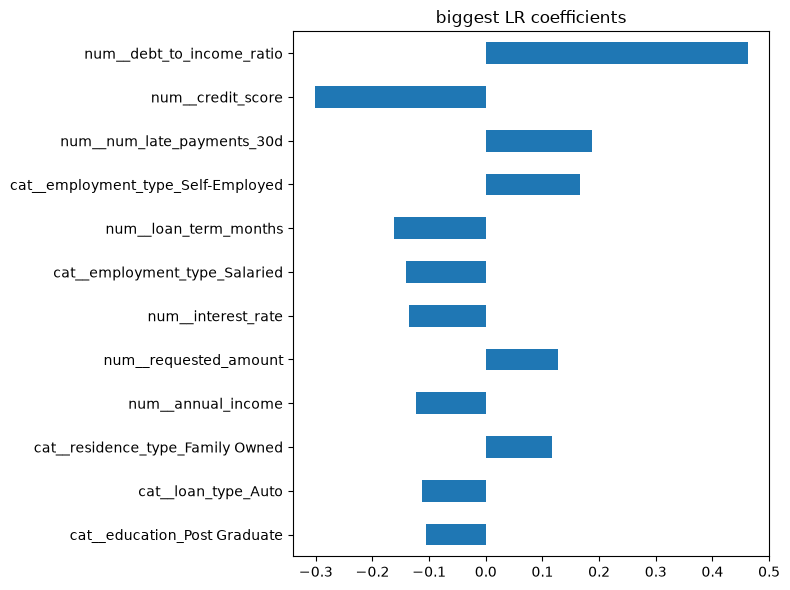

In [5]:
lr = models["logistic_regression"]
coefs = pd.Series(lr["model"].coef_[0], index=lr["prep"].get_feature_names_out())
coefs.sort_values(key=abs).tail(12).plot.barh(figsize=(8, 6), title="biggest LR coefficients")
plt.tight_layout()

## Notes

- Logistic Regression is better than the tree (AUC ~0.74 vs ~0.70).
- Recall at 0.5 is ~0.65, under the 0.70 target. Changing the threshold will help but AUC
  still needs to get closer to 0.80, so Random Forest / XGBoost next.
- Biggest drivers: debt-to-income, credit score, 30-day late payments, income and
  employment type (self-employed riskier, salaried safer).